In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import sklearn
import networkx as nx
import neo4j

print("Semua library utama berhasil diimpor!")
print("pandas:", pd.__version__)
print("numpy:", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("networkx:", nx.__version__)
print("neo4j:", neo4j.__version__)

Semua library utama berhasil diimpor!
pandas: 3.0.6
numpy: 2.4.6
scikit-learn: 1.9.1
networkx: 3.6.1
neo4j: 4.2.1


PEMERIKSAAN DATASET

In [4]:
import pandas as pd
from pathlib import Path

csv_path = Path("E:/kuliah/UTS GRAF SAINS DATA/data/events.csv")

events = pd.read_csv(csv_path)

print("Ukuran dataset:", events.shape)
print("\nNama kolom:")
print(events.columns.tolist())

print("\nLima baris pertama:")
display(events.head())

print("\nInformasi tipe data:")
events.info()

print("\nJumlah data kosong:")
print(events.isna().sum())

print("\nDistribusi event:")
print(events["event"].value_counts())

Ukuran dataset: (2756101, 5)

Nama kolom:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

Lima baris pertama:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN



Informasi tipe data:
<class 'pandas.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          str    
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), str(1)
memory usage: 105.1 MB

Jumlah data kosong:
timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64

Distribusi event:
event
view           2664312
addtocart        69332
transaction      22457
Name: count, dtype: int64


PERIKSA RENTANG WAKTU DATASET

In [53]:

import pandas as pd

# Periksa rentang timestamp asli.
print("Timestamp terkecil:", events["timestamp"].min())
print("Timestamp terbesar:", events["timestamp"].max())

# RetailRocket umumnya menggunakan Unix epoch dalam milidetik.
events["datetime"] = pd.to_datetime(
    events["timestamp"],
    unit="ms",
    errors="coerce",
    utc=True
)

print("\nTanggal paling awal:", events["datetime"].min())
print("Tanggal paling akhir:", events["datetime"].max())

print("\nJumlah timestamp yang gagal dikonversi:",
      events["datetime"].isna().sum())


Timestamp terkecil: 1430622004384
Timestamp terbesar: 1442545187788

Tanggal paling awal: 2015-05-03 03:00:04.384000+00:00
Tanggal paling akhir: 2015-09-18 02:59:47.788000+00:00

Jumlah timestamp yang gagal dikonversi: 0


PERIKSA DISTRIBUSI DATA PER BULAN

In [54]:
events["datetime"] = pd.to_datetime(
    events["timestamp"],
    unit="ms",
    utc=True
)

events["month"] = events["datetime"].dt.strftime("%Y-%m")

monthly_counts = (
    events.groupby("month")
    .size()
    .rename("jumlah_event")
    .to_frame()
)

display(monthly_counts)

,jumlah_event
month,
2015-05,590652
2015-06,610393
2015-07,697984
2015-08,553362
2015-09,303710


FILTER DAN SIMPAN CSV UNTUK P1 DAN P2

In [95]:
import pandas as pd

# Pastikan kolom datetime sudah bertipe datetime UTC
events["datetime"] = pd.to_datetime(
    events["timestamp"],
    unit="ms",
    utc=True
)

# =========================
# P1: TRAINING
# =========================
p1_mulai = pd.Timestamp("2015-05-03 00:00:00", tz="UTC")
p1_akhir = pd.Timestamp("2015-09-01 00:00:00", tz="UTC")

p1 = events[
    (events["datetime"] >= p1_mulai) &
    (events["datetime"] < p1_akhir)
].copy()

# =========================
# P2: TESTING
# =========================
p2_mulai = pd.Timestamp("2015-09-01 00:00:00", tz="UTC")
p2_akhir = pd.Timestamp("2015-09-19 00:00:00", tz="UTC")

p2 = events[
    (events["datetime"] >= p2_mulai) &
    (events["datetime"] < p2_akhir)
].copy()

# =========================
# SIMPAN CSV
# =========================
p1.drop(columns=["datetime"], errors="ignore").to_csv(
    "events_P1_training.csv", index=False
)

p2.drop(columns=["datetime"], errors="ignore").to_csv(
    "events_P2_testing.csv", index=False
)

# =========================
# HASIL PEMBAGIAN DATA
# =========================
print("\nJumlah event P1:", len(p1))
print("Jumlah event P2:", len(p2))

print("\nDistribusi event P1:")
print(p1["event"].value_counts())

print("\nDistribusi event P2:")
print(p2["event"].value_counts())

print("\nRentang tanggal P1:")
print(p1["datetime"].min(), "sampai", p1["datetime"].max())

print("\nRentang tanggal P2:")
print(p2["datetime"].min(), "sampai", p2["datetime"].max())


Jumlah event P1: 2452391
Jumlah event P2: 303710

Distribusi event P1:
event
view           2370652
addtocart        61651
transaction      20088
Name: count, dtype: int64

Distribusi event P2:
event
view           293660
addtocart        7681
transaction      2369
Name: count, dtype: int64

Rentang tanggal P1:
2015-05-03 03:00:04.384000+00:00 sampai 2015-08-31 23:59:58.647000+00:00

Rentang tanggal P2:
2015-09-01 00:00:02.005000+00:00 sampai 2015-09-18 02:59:47.788000+00:00


In [96]:
import pandas as pd

# =====================================
# 1. CEK RENTANG UNIX TIMESTAMP ASLI
# =====================================
print("Timestamp terkecil:", events["timestamp"].min())
print("Timestamp terbesar:", events["timestamp"].max())

# =====================================
# 2. TENTUKAN PERIODE TRAINING & TESTING
# =====================================
# Training: 3 Mei - 31 Agustus 2015
# Testing : 1 September - 18 September 2015

# Mengubah tanggal batas menjadi Unix milidetik
# (batas awal termasuk, batas akhir tidak termasuk)
p1_awal = 1430611200000  # 2015-05-03 00:00:00 UTC
p1_akhir = 1441065600000 # 2015-09-01 00:00:00 UTC

p2_awal = 1441065600000  # 2015-09-01 00:00:00 UTC
p2_akhir = 1442620800000 # 2015-09-19 00:00:00 UTC

# =====================================
# 3. FILTER DATA
# =====================================
p1 = events[
    (events["timestamp"] >= p1_awal) &
    (events["timestamp"] < p1_akhir)
].copy()

p2 = events[
    (events["timestamp"] >= p2_awal) &
    (events["timestamp"] < p2_akhir)
].copy()

# =====================================
# 4. LIHAT TIMESTAMP ASLI HASIL FILTER
# =====================================
print("\n=== TRAINING (P1) ===")
print("Timestamp awal aktual:", p1["timestamp"].min())
print("Timestamp akhir aktual:", p1["timestamp"].max())
print("Jumlah event:", len(p1))

print("\n=== TESTING (P2) ===")
print("Timestamp awal aktual:", p2["timestamp"].min())
print("Timestamp akhir aktual:", p2["timestamp"].max())
print("Jumlah event:", len(p2))

Timestamp terkecil: 1430622004384
Timestamp terbesar: 1442545187788

=== TRAINING (P1) ===
Timestamp awal aktual: 1430622004384
Timestamp akhir aktual: 1441065598647
Jumlah event: 2452391

=== TESTING (P2) ===
Timestamp awal aktual: 1441065602005
Timestamp akhir aktual: 1442545187788
Jumlah event: 303710


PEMERIKSAAN AKHIR SEBELUM IMPORT KE NEO47

In [56]:
def ringkasan_periode(df, nama):
    print(f"\n===== {nama} =====")
    print("Total event:", len(df))
    print("Jumlah user unik:", df["visitorid"].nunique())
    print("Jumlah item unik:", df["itemid"].nunique())
    print("Jumlah transaction ID unik:",
          df["transactionid"].nunique())
    print("\nJumlah user per jenis event:")
    print(
        df.groupby("event")["visitorid"]
        .nunique()
        .sort_values(ascending=False)
    )

ringkasan_periode(p1, "P1 - Training")
ringkasan_periode(p2, "P2 - Testing")


===== P1 - Training =====
Total event: 2452391
Jumlah user unik: 1250856
Jumlah item unik: 222982
Jumlah transaction ID unik: 15825

Jumlah user per jenis event:
event
view           1247951
addtocart        33586
transaction      10500
Name: visitorid, dtype: int64

===== P2 - Testing =====
Total event: 303710
Jumlah user unik: 173728
Jumlah item unik: 82220
Jumlah transaction ID unik: 1847

Jumlah user per jenis event:
event
view           173169
addtocart        4331
transaction      1290
Name: visitorid, dtype: int64


PERIKSA KESIAPAN DATA UNTUK GRAF

In [57]:
print("P1 - baris duplikat:", p1.duplicated().sum())
print("P1 - user kosong:", p1["visitorid"].isna().sum())
print("P1 - item kosong:", p1["itemid"].isna().sum())

print("\nContoh data P1:")
display(p1.head())

print("\nJumlah interaksi per user di P1:")
display(
    p1.groupby("visitorid")
    .size()
    .describe()
    .to_frame("jumlah_event_per_user")
)

P1 - baris duplikat: 408
P1 - user kosong: 0
P1 - item kosong: 0

Contoh data P1:


,timestamp,visitorid,event,itemid,transactionid,datetime,month
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117000+00:00,2015-06
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164000+00:00,2015-06
2,1433221999827,111016,view,318965,NaN,2015-06-02 05:13:19.827000+00:00,2015-06
3,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914000+00:00,2015-06
4,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106000+00:00,2015-06



Jumlah interaksi per user di P1:


,jumlah_event_per_user
count,1.250856e+06
mean,1.960570e+00
std,1.198605e+01
min,1.000000e+00
25%,1.000000e+00
50%,1.000000e+00
75%,2.000000e+00
max,6.683000e+03


KONEKSI KE NEO4J

UJI KONEKSI

In [58]:
from neo4j import GraphDatabase

URI = "bolt://localhost:7687"
USERNAME = "neo4j"
PASSWORD = "arina*T1Y4S"

driver = GraphDatabase.driver(
    URI,
    auth=(USERNAME, PASSWORD)
)

driver.verify_connectivity()

print("Python berhasil terhubung ke Neo4j!")

Python berhasil terhubung ke Neo4j!


C:\Users\asus\AppData\Local\Temp\ipykernel_16292\3494490596.py:12: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


In [59]:
with driver.session() as session:
    result = session.run(
        "RETURN 'Koneksi Python berhasil' AS pesan"
    )

    for record in result:
        print(record["pesan"])

Koneksi Python berhasil


In [60]:
driver.close()

PASTIKAN DATA P1 SIAP

In [61]:
print("Ukuran P1:", p1.shape)
print("Kolom:", p1.columns.tolist())
print("\nDistribusi event:")
print(p1["event"].value_counts())

Ukuran P1: (2452391, 7)
Kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid', 'datetime', 'month']

Distribusi event:
event
view           2370652
addtocart        61651
transaction      20088
Name: count, dtype: int64


PERSIAPKAN DATA DI PYTHON

In [62]:
# Pastikan hanya memakai data P1
import pandas as pd

kolom_diperlukan = [
    "timestamp",
    "visitorid",
    "event",
    "itemid",
    "transactionid"
]

assert all(col in p1.columns for col in kolom_diperlukan)

# Buat salinan khusus untuk proses import
import_df = p1[kolom_diperlukan].copy()

# Buat ID unik untuk setiap baris event
import_df["eventId"] = range(len(import_df))

# Ubah transactionid kosong menjadi None
import_df["transactionid"] = (
    import_df["transactionid"].where(
        import_df["transactionid"].notna(), None
    )
)

print("Jumlah baris yang akan diimpor:", len(import_df))
print("Jumlah event ID unik:", import_df["eventId"].nunique())
print("\nDistribusi event:")
print(import_df["event"].value_counts())

Jumlah baris yang akan diimpor: 2452391
Jumlah event ID unik: 2452391

Distribusi event:
event
view           2370652
addtocart        61651
transaction      20088
Name: count, dtype: int64


IMPORT P1 DARI PYTHON KE NEO4J

In [63]:
driver.verify_connectivity()
print("Koneksi Neo4j berhasil.")

C:\Users\asus\AppData\Local\Temp\ipykernel_16292\466475002.py:1: ExperimentalWarning: The configuration may change in the future.
  driver.verify_connectivity()


Koneksi Neo4j berhasil.


PERIKSA JUMLAH NODE

In [64]:
with driver.session(database="neo4j") as session:
    result = session.run("""
        MATCH (n)
        RETURN count(n) AS jumlah_node
    """)
    print("Jumlah node sebelum import:", result.single()["jumlah_node"])

Jumlah node sebelum import: 1473842


KODE IMPORT

In [65]:
# Pastikan import_df sudah dibuat pada tahap sebelumnya.
# Kolom eventId harus unik untuk setiap baris.

from time import time

BATCH_SIZE = 5000

IMPORT_QUERY = """
UNWIND $rows AS row

MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})

FOREACH (_ IN CASE
    WHEN row.event = 'view' THEN [1]
    ELSE []
END |
    MERGE (v)-[r:VIEWED {eventId: row.eventId}]->(i)
    SET r.timestamp = row.timestamp
)

FOREACH (_ IN CASE
    WHEN row.event = 'addtocart' THEN [1]
    ELSE []
END |
    MERGE (v)-[r:ADDED_TO_CART {eventId: row.eventId}]->(i)
    SET r.timestamp = row.timestamp
)

FOREACH (_ IN CASE
    WHEN row.event = 'transaction' THEN [1]
    ELSE []
END |
    MERGE (v)-[r:BOUGHT {eventId: row.eventId}]->(i)
    SET r.timestamp = row.timestamp,
        r.transactionId = row.transactionid)
"""

total_rows = len(import_df)
start_time = time()

with driver.session(database="neo4j") as session:
    for start in range(0, total_rows, BATCH_SIZE):
        end = min(start + BATCH_SIZE, total_rows)

        # Konversi hanya batch yang sedang diproses
        batch = import_df.iloc[start:end].to_dict("records")

        result = session.run(IMPORT_QUERY, rows=batch)
        result.consume()

        if end % 100000 < BATCH_SIZE or end == total_rows:
            elapsed = time() - start_time
            print(
                f"Progress: {end:,}/{total_rows:,} event "
                f"({end / total_rows:.1%}) | "
                f"Waktu: {elapsed:.1f} detik"
            )

print("Import P1 selesai!")

Progress: 100,000/2,452,391 event (4.1%) | Waktu: 31.8 detik
Progress: 200,000/2,452,391 event (8.2%) | Waktu: 54.9 detik
Progress: 300,000/2,452,391 event (12.2%) | Waktu: 77.4 detik
Progress: 400,000/2,452,391 event (16.3%) | Waktu: 99.7 detik
Progress: 500,000/2,452,391 event (20.4%) | Waktu: 120.7 detik
Progress: 600,000/2,452,391 event (24.5%) | Waktu: 140.8 detik
Progress: 700,000/2,452,391 event (28.5%) | Waktu: 159.5 detik
Progress: 800,000/2,452,391 event (32.6%) | Waktu: 180.5 detik
Progress: 900,000/2,452,391 event (36.7%) | Waktu: 217.2 detik
Progress: 1,000,000/2,452,391 event (40.8%) | Waktu: 242.7 detik
Progress: 1,100,000/2,452,391 event (44.9%) | Waktu: 273.2 detik
Progress: 1,200,000/2,452,391 event (48.9%) | Waktu: 305.9 detik
Progress: 1,300,000/2,452,391 event (53.0%) | Waktu: 332.3 detik
Progress: 1,400,000/2,452,391 event (57.1%) | Waktu: 361.6 detik
Progress: 1,500,000/2,452,391 event (61.2%) | Waktu: 384.1 detik
Progress: 1,600,000/2,452,391 event (65.2%) | Wak

BUAT MATRIKS SPARSE DARI P1
Nilai 1 jika pengguna pernah berinteraksi dengan item, dan 0 jika tidak. Jika pengguna melakukan beberapa jenis interaksi dengan item yang sama, item tersebut tetap bernilai 1

In [66]:
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix

# Gunakan data P1 yang sudah difilter
vsm_data = p1[["visitorid", "itemid"]].drop_duplicates()

# Buat indeks pengguna dan item
user_ids = pd.Index(vsm_data["visitorid"].unique())
item_ids = pd.Index(vsm_data["itemid"].unique())

user_index = user_ids.get_indexer(vsm_data["visitorid"])
item_index = item_ids.get_indexer(vsm_data["itemid"])

# Bentuk matriks User–Item sparse
user_item_matrix = csr_matrix(
    (
        np.ones(len(vsm_data), dtype=np.int8),
        (user_index, item_index)
    ),
    shape=(len(user_ids), len(item_ids)),
    dtype=np.int8
)

print("Ukuran matriks User–Item:", user_item_matrix.shape)
print("Jumlah interaksi user-item unik:", user_item_matrix.nnz)
print("Jumlah pengguna:", len(user_ids))
print("Jumlah item:", len(item_ids))
print("Kepadatan matriks:",
      f"{user_item_matrix.nnz / (user_item_matrix.shape[0] * user_item_matrix.shape[1]):.6%}")

Ukuran matriks User–Item: (1250856, 222982)
Jumlah interaksi user-item unik: 1905695
Jumlah pengguna: 1250856
Jumlah item: 222982
Kepadatan matriks: 0.000683%


BENTUK VSM PENGGUNA DAN VSM ITEM

In [67]:
# Baris = pengguna, kolom = item
user_vsm = user_item_matrix

# Baris = item, kolom = pengguna
item_vsm = user_item_matrix.T.tocsr()

print("User VSM:", user_vsm.shape)
print("Item VSM:", item_vsm.shape)

User VSM: (1250856, 222982)
Item VSM: (222982, 1250856)


VISUALISASIKAN CONTOH MATRIKS

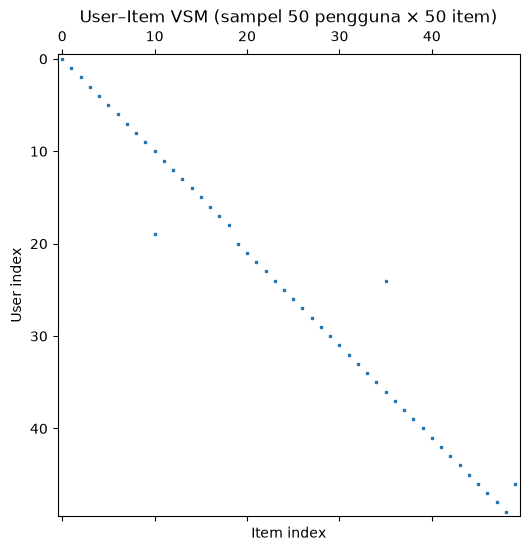

In [68]:
import matplotlib.pyplot as plt

sample_size = min(50, user_vsm.shape[0])
sample_matrix = user_vsm[:sample_size, :50].toarray()

plt.figure(figsize=(12, 6))
plt.spy(sample_matrix, markersize=2)
plt.title("User–Item VSM (sampel 50 pengguna × 50 item)")
plt.xlabel("Item index")
plt.ylabel("User index")
plt.show()

Titik-titik yang terlihat menunjukkan interaksi. Area kosong menunjukkan pasangan pengguna–item yang tidak memiliki interaksi dalam sampel tersebut

BANDINGKAN PROYEKSI USER DAN ITEM

In [69]:
from sklearn.metrics.pairwise import cosine_similarity

# Sampel untuk demonstrasi, bukan seluruh dataset
n_users_sample = min(500, user_vsm.shape[0])
n_items_sample = min(500, item_vsm.shape[0])

user_sample = user_vsm[:n_users_sample]
item_sample = item_vsm[:n_items_sample]

user_similarity_sample = cosine_similarity(user_sample)
item_similarity_sample = cosine_similarity(item_sample)

print("User similarity sample:",
      user_similarity_sample.shape)

print("Item similarity sample:",
      item_similarity_sample.shape)

User similarity sample: (500, 500)
Item similarity sample: (500, 500)


PILIH SAMPEL SECARA ACAK

In [70]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

rng = np.random.default_rng(42)

n_user_sample = min(100, user_vsm.shape[0])
n_item_sample = min(100, item_vsm.shape[0])

user_idx = np.sort(
    rng.choice(user_vsm.shape[0], n_user_sample, replace=False)
)
item_idx = np.sort(
    rng.choice(item_vsm.shape[0], n_item_sample, replace=False)
)

user_sample = user_vsm[user_idx]
item_sample = item_vsm[item_idx]

user_sim = cosine_similarity(user_sample)
item_sim = cosine_similarity(item_sample)

print("User–User similarity:", user_sim.shape)
print("Item–Item similarity:", item_sim.shape)

User–User similarity: (100, 100)
Item–Item similarity: (100, 100)


BUAT GRAF PROYEKSI DENGAN EDGE SIMILIARITY MINIMAL 0.1 DAN SELF LOOP DIHILANGKAN

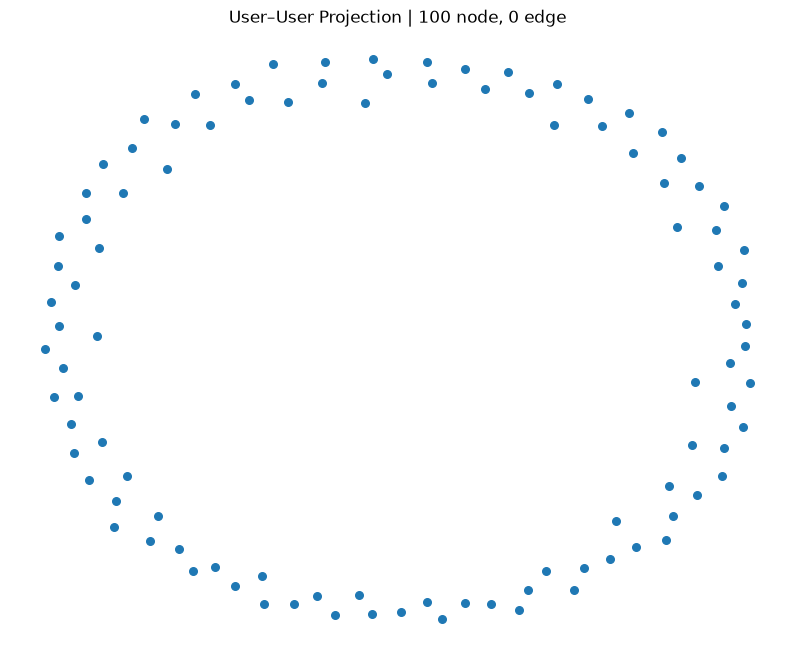

Jumlah node: 100
Jumlah edge: 0


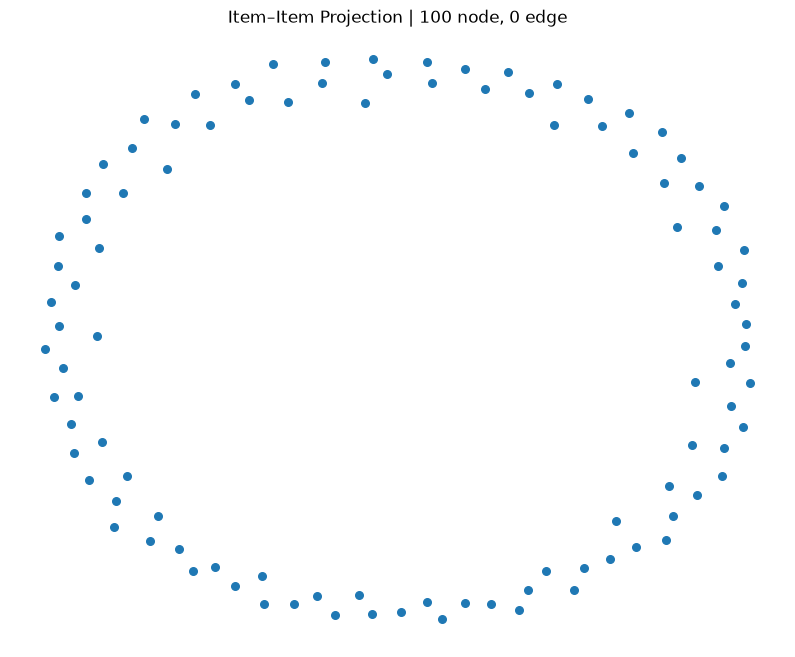

Jumlah node: 100
Jumlah edge: 0


In [71]:
import networkx as nx
import matplotlib.pyplot as plt

def plot_projection(similarity, title, threshold=0.1):
    G = nx.Graph()
    n = similarity.shape[0]
    G.add_nodes_from(range(n))

    for i in range(n):
        for j in range(i + 1, n):
            score = similarity[i, j]
            if score >= threshold:
                G.add_edge(i, j, weight=float(score))

    plt.figure(figsize=(10, 8))
    pos = nx.spring_layout(G, seed=42)

    nx.draw_networkx(
        G,
        pos=pos,
        with_labels=False,
        node_size=30,
        width=0.7
    )

    plt.title(
        f"{title} | {G.number_of_nodes()} node, "
        f"{G.number_of_edges()} edge"
    )
    plt.axis("off")
    plt.show()

    print("Jumlah node:", G.number_of_nodes())
    print("Jumlah edge:", G.number_of_edges())

    return G

G_user = plot_projection(user_sim, "User–User Projection")
G_item = plot_projection(item_sim, "Item–Item Projection")

PERIKSA SIMILIARITY APAKAH MEMANG NOL

In [72]:
print("USER SIMILARITY")
print("Nilai maksimum:", user_sim.max())
print("Nilai minimum:", user_sim.min())

upper_user = user_sim[np.triu_indices_from(user_sim, k=1)]
print("Pasangan dengan similarity > 0:", (upper_user > 0).sum())
print("Pasangan dengan similarity >= 0.1:", (upper_user >= 0.1).sum())

print("\nITEM SIMILARITY")
upper_item = item_sim[np.triu_indices_from(item_sim, k=1)]
print("Nilai maksimum:", item_sim.max())
print("Pasangan dengan similarity > 0:", (upper_item > 0).sum())
print("Pasangan dengan similarity >= 0.1:", (upper_item >= 0.1).sum())

USER SIMILARITY
Nilai maksimum: 1.0000000000000002
Nilai minimum: 0.0
Pasangan dengan similarity > 0: 0
Pasangan dengan similarity >= 0.1: 0

ITEM SIMILARITY
Nilai maksimum: 1.0000000000000007
Pasangan dengan similarity > 0: 0
Pasangan dengan similarity >= 0.1: 0


COBA TRESHOLD LEBIH RENDAH

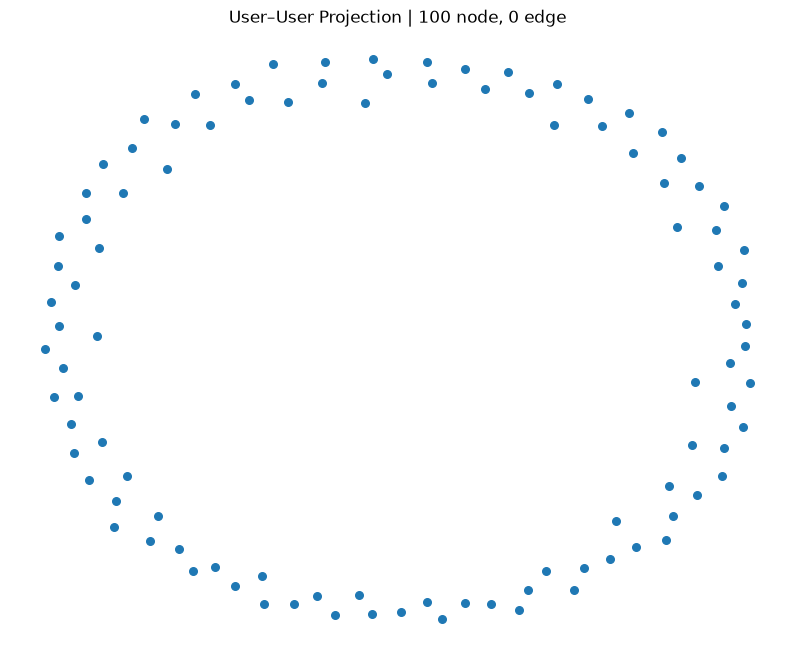

Jumlah node: 100
Jumlah edge: 0


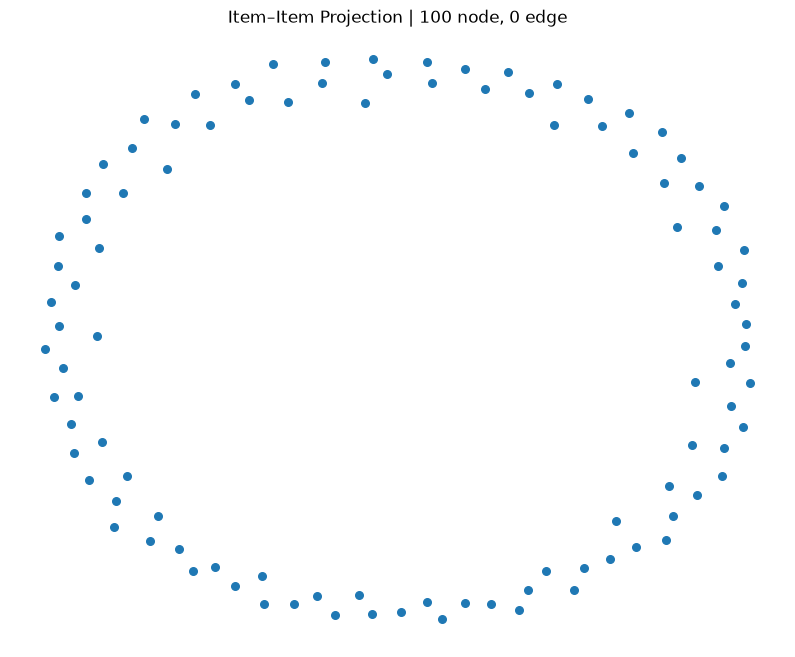

Jumlah node: 100
Jumlah edge: 0


In [73]:
G_user = plot_projection(
    user_sim,
    "User–User Projection",
    threshold=0.01
)

G_item = plot_projection(
    item_sim,
    "Item–Item Projection",
    threshold=0.01
)

PILIH USER DAN ITEM YANG PALING AKTIF

In [74]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity

# 1. Pilih 100 user paling aktif
top_users = (
    vsm_data.groupby("visitorid")["itemid"]
    .nunique()
    .nlargest(100)
    .index
)

user_idx = user_ids.get_indexer(top_users)
user_sample = user_vsm[user_idx]
user_sim = cosine_similarity(user_sample)

# 2. Pilih 100 item paling populer
top_items = (
    vsm_data.groupby("itemid")["visitorid"]
    .nunique()
    .nlargest(100)
    .index
)

item_idx = item_ids.get_indexer(top_items)
item_sample = item_vsm[item_idx]
item_sim = cosine_similarity(item_sample)

# 3. Periksa similarity antarobjek yang berbeda
upper_user = user_sim[np.triu_indices_from(user_sim, k=1)]
upper_item = item_sim[np.triu_indices_from(item_sim, k=1)]

print("USER SIMILARITY")
print("Jumlah pasangan similarity > 0:", (upper_user > 0).sum())
print("Jumlah pasangan similarity >= 0.1:", (upper_user >= 0.1).sum())
print("Similarity maksimum antar-user:", upper_user.max())

print("\nITEM SIMILARITY")
print("Jumlah pasangan similarity > 0:", (upper_item > 0).sum())
print("Jumlah pasangan similarity >= 0.1:", (upper_item >= 0.1).sum())
print("Similarity maksimum antar-item:", upper_item.max())

USER SIMILARITY
Jumlah pasangan similarity > 0: 4594
Jumlah pasangan similarity >= 0.1: 174
Similarity maksimum antar-user: 0.24760044495126168

ITEM SIMILARITY
Jumlah pasangan similarity > 0: 2732
Jumlah pasangan similarity >= 0.1: 16
Similarity maksimum antar-item: 0.1939075940138191


BUAT VISUALISASI PROYEKSI

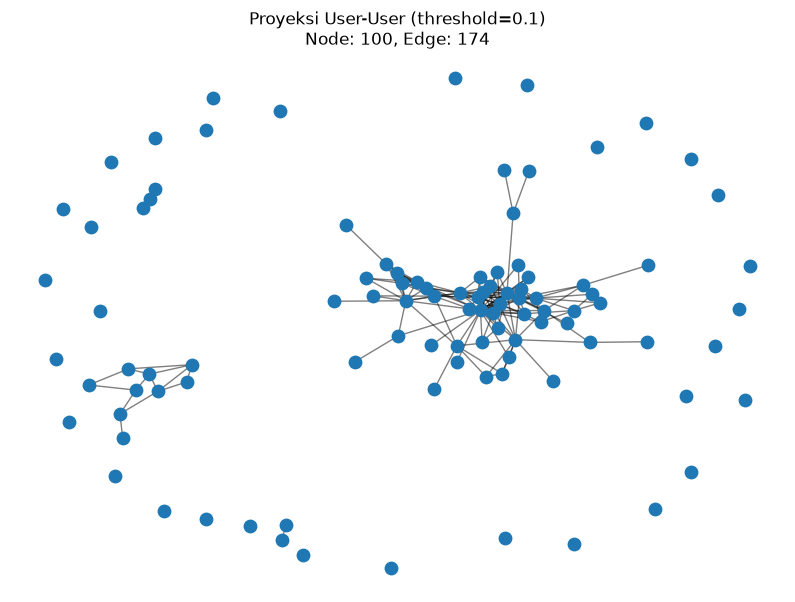

Proyeksi User-User
Jumlah node: 100
Jumlah edge: 174


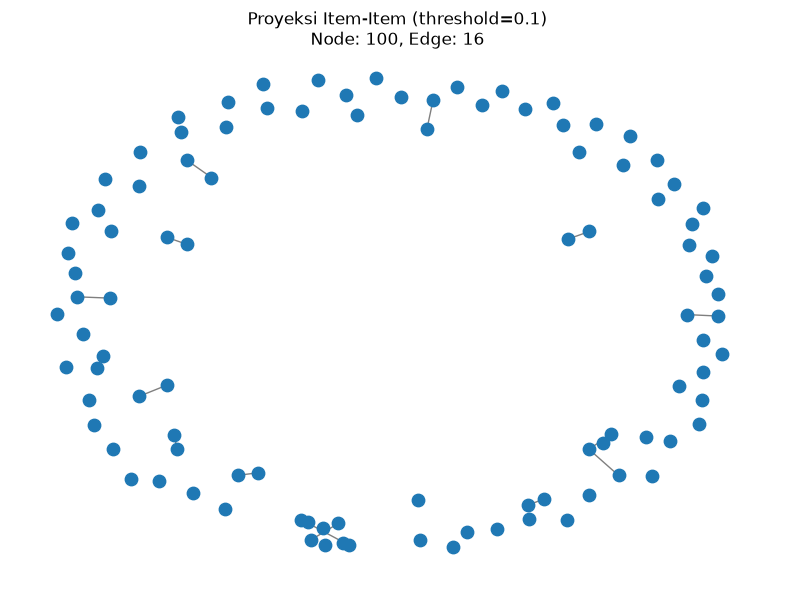

Proyeksi Item-Item
Jumlah node: 100
Jumlah edge: 16


In [75]:
import networkx as nx
import matplotlib.pyplot as plt

def plot_projection(sim_matrix, title, threshold=0.1):
    G = nx.Graph()
    G.add_nodes_from(range(sim_matrix.shape[0]))

    for i in range(sim_matrix.shape[0]):
        for j in range(i + 1, sim_matrix.shape[1]):
            similarity = sim_matrix[i, j]
            if similarity >= threshold:
                G.add_edge(i, j, weight=float(similarity))

    plt.figure(figsize=(10, 7))
    pos = nx.spring_layout(G, seed=42)

    nx.draw_networkx_nodes(
        G, pos,
        node_size=80
    )
    nx.draw_networkx_edges(
        G, pos,
        alpha=0.5,
        width=1
    )

    plt.title(
        f"{title} (threshold={threshold})\n"
        f"Node: {G.number_of_nodes()}, "
        f"Edge: {G.number_of_edges()}"
    )
    plt.axis("off")
    plt.show()

    print(f"{title}")
    print("Jumlah node:", G.number_of_nodes())
    print("Jumlah edge:", G.number_of_edges())

    return G

G_user = plot_projection(
    user_sim, "Proyeksi User-User", threshold=0.1
)

G_item = plot_projection(
    item_sim, "Proyeksi Item-Item", threshold=0.1
)

BUAT DATA PASANGAN USER YANG MIRIP

In [76]:
import numpy as np
import pandas as pd

THRESHOLD = 0.1

# Ambil hanya segitiga atas agar tidak menyimpan A-B dan B-A dua kali
i_idx, j_idx = np.triu_indices_from(user_sim, k=1)

mask = user_sim[i_idx, j_idx] >= THRESHOLD

user_similarity_df = pd.DataFrame({
    "user1": user_ids[user_idx[i_idx[mask]]],
    "user2": user_ids[user_idx[j_idx[mask]]],
    "similarity": user_sim[i_idx[mask], j_idx[mask]]
})

print("Jumlah relasi User–User:", len(user_similarity_df))
display(user_similarity_df.head(10))

Jumlah relasi User–User: 174


,user1,user2,similarity
0,1150086,530559,0.247600
1,1150086,895999,0.156217
2,1150086,371606,0.200029
3,1150086,163561,0.111798
4,1150086,684514,0.172419
5,1150086,1297062,0.186220
6,1150086,861299,0.145166
7,1150086,85734,0.105290
8,1150086,836635,0.145772
9,1150086,152963,0.137396


SIMPAN KE NEO4J

In [77]:
SAVE_USER_SIMILARITY = """
UNWIND $rows AS row
MATCH (u1:Visitor {visitorId: row.user1})
MATCH (u2:Visitor {visitorId: row.user2})
MERGE (u1)-[r:SIMILAR_TO]->(u2)
SET r.similarity = row.similarity
"""

records = user_similarity_df.to_dict("records")

with driver.session(database="neo4j") as session:
    for start in range(0, len(records), 1000):
        session.run(
            SAVE_USER_SIMILARITY,
            rows=records[start:start + 1000]
        ).consume()

print("Relasi similarity User–User berhasil disimpan.")

Relasi similarity User–User berhasil disimpan.


MEMBUAT REKOMENDASI TOP 5 DENGAN KNN

SIAPKAN MATRIKS TETANGGA

In [78]:
from sklearn.neighbors import NearestNeighbors

knn = NearestNeighbors(
    metric="cosine",
    algorithm="brute",
    n_neighbors=6,
    n_jobs=-1
)

knn.fit(user_vsm)
print("Model KNN berhasil dibuat.")

Model KNN berhasil dibuat.


PILIH PENGGUNA AKTIF

In [79]:
user_activity = np.asarray(user_vsm.sum(axis=1)).ravel()
active_idx = np.flatnonzero(user_activity >= 5)

example_idx = active_idx[0]
example_user_id = user_ids[example_idx]

print("Contoh visitorId:", example_user_id)
print("Jumlah item yang pernah diinteraksikan:",
      user_activity[example_idx])

Contoh visitorId: 992329
Jumlah item yang pernah diinteraksikan: 24


CARI TETANGGA TERDEKAT UNTUK SATU PENGGUNA

In [80]:
distances, indices = knn.kneighbors(
    user_vsm[example_idx],
    n_neighbors=6
)

neighbors = []

for distance, idx in zip(distances[0], indices[0]):
    if idx == example_idx:
        continue

    neighbors.append({
        "visitorid": int(user_ids[idx]),
        "similarity": float(1 - distance)
    })

neighbors_df = pd.DataFrame(neighbors)

display(neighbors_df)

,visitorid,similarity
0,1221831,0.288675
1,1368304,0.288675
2,872467,0.288675
3,51202,0.288675
4,932758,0.288675


BUAT REKOMENDASI ITEM DARI TETANGGA

In [81]:
from collections import defaultdict

scores = defaultdict(float)

for neighbor in neighbors:
    neighbor_idx = user_ids.get_loc(neighbor["visitorid"])
    interacted_items = user_vsm[neighbor_idx].indices

    for item_idx_value in interacted_items:
        scores[item_idx_value] += neighbor["similarity"]

seen_items = set(user_vsm[example_idx].indices)

recommendations = [
    (idx, score)
    for idx, score in scores.items()
    if idx not in seen_items
]

recommendations.sort(key=lambda x: x[1], reverse=True)

top5 = recommendations[:5]

recommendation_df = pd.DataFrame({
    "itemid": [int(item_ids[idx]) for idx, _ in top5],
    "score": [score for _, score in top5]
})

display(recommendation_df)

,itemid,score


SIAPKAN MODEL KNN

In [82]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import pandas as pd

# Hitung jumlah item unik yang diinteraksikan setiap user
user_activity = np.asarray(user_vsm.sum(axis=1)).ravel()

# Pilih user yang memiliki setidaknya 5 interaksi
active_idx = np.flatnonzero(user_activity >= 5)

print("Jumlah user dengan minimal 5 interaksi:", len(active_idx))

Jumlah user dengan minimal 5 interaksi: 35329


PILIH SATU PENGGUNA

In [83]:
example_idx = active_idx[0]
example_user_id = int(user_ids[example_idx])

print("Visitor ID:", example_user_id)
print("Jumlah item yang pernah diinteraksikan:",
      int(user_activity[example_idx]))

Visitor ID: 992329
Jumlah item yang pernah diinteraksikan: 24


CARI 5 TETANGGA TERDEKAT

In [84]:
from sklearn.metrics.pairwise import cosine_similarity

# user_idx berisi indeks 100 pengguna sampel teraktif
candidate_user_matrix = user_vsm[user_idx]

similarities = cosine_similarity(
    user_vsm[example_idx],
    candidate_user_matrix
).ravel()

# Urutkan dari similarity terbesar
order = np.argsort(similarities)[::-1]

neighbors = []

for pos in order:
    candidate_idx = user_idx[pos]

    # Jangan merekomendasikan pengguna itu sendiri
    if candidate_idx == example_idx:
        continue

    if similarities[pos] > 0:
        neighbors.append({
            "visitorid": int(user_ids[candidate_idx]),
            "similarity": float(similarities[pos]),
            "matrix_index": int(candidate_idx)
        })

    if len(neighbors) == 5:
        break

neighbors_df = pd.DataFrame(neighbors)
display(neighbors_df)

,visitorid,similarity,matrix_index
0,527307,0.057096,2017
1,1376763,0.049969,1112927
2,77390,0.049834,1976
3,856874,0.039123,1965
4,896066,0.025126,19196


HASILKAN REKOMENDASI ITEM TOP 5

In [85]:
from collections import defaultdict

scores = defaultdict(float)

for neighbor in neighbors:
    neighbor_idx = neighbor["matrix_index"]
    interacted_items = user_vsm[neighbor_idx].indices

    for item_idx_value in interacted_items:
        scores[item_idx_value] += neighbor["similarity"]

# Item yang sudah pernah dilihat atau diinteraksikan user target
seen_items = set(user_vsm[example_idx].indices)

recommendations = [
    (idx, score)
    for idx, score in scores.items()
    if idx not in seen_items
]

recommendations.sort(key=lambda x: x[1], reverse=True)

top5 = recommendations[:5]

recommendation_df = pd.DataFrame({
    "itemid": [int(item_ids[idx]) for idx, _ in top5],
    "score": [float(score) for _, score in top5]
})

display(recommendation_df)

,itemid,score
0,34843,0.121345
1,275294,0.121345
2,76196,0.107065
3,268883,0.107065
4,334481,0.107065


EVALUASI MENGGUNAKAN P2

In [86]:
print("Jumlah baris P2:", len(p2))
print("Kolom:", p2.columns.tolist())

Jumlah baris P2: 303710
Kolom: ['timestamp', 'visitorid', 'event', 'itemid', 'transactionid', 'datetime', 'month']


PILIH TARGET USER DAN CARI 5 TETANGGA TERDEKAT

In [87]:

import numpy as np
import pandas as pd

# Cari user sampel dengan total similarity terbesar
sim_no_diag = user_sim.copy()
np.fill_diagonal(sim_no_diag, 0)

target_pos = int(np.argmax(sim_no_diag.sum(axis=1)))
example_idx = int(user_idx[target_pos])
example_user_id = int(user_ids[example_idx])

print("Target Visitor ID:", example_user_id)
print("Jumlah item unik di data training:",
      int(user_vsm[example_idx].nnz))
print("Jumlah user serupa dalam sampel:",
      int(np.sum(user_sim[target_pos] > 0) - 0))


Target Visitor ID: 1150086
Jumlah item unik di data training: 3334
Jumlah user serupa dalam sampel: 100


AMBIL 5 TETANGGA DENGAN SIMILIARITY TERBESAR (TIDAK TERMASUK DIRINYA SENDIRI)

In [88]:

neighbor_order = np.argsort(user_sim[target_pos])[::-1]

neighbors = []
for pos in neighbor_order:
    candidate_idx = int(user_idx[pos])

    if candidate_idx == example_idx:
        continue

    sim = float(user_sim[target_pos, pos])
    if sim <= 0:
        continue

    neighbors.append({
        "visitorid": int(user_ids[candidate_idx]),
        "similarity": sim,
        "matrix_index": candidate_idx
    })

    if len(neighbors) == 5:
        break

neighbors_df = pd.DataFrame(neighbors)
display(neighbors_df)

print("Jumlah tetangga yang ditemukan:", len(neighbors_df))


,visitorid,similarity,matrix_index
0,530559,0.247600,140163
1,371606,0.200029,254373
2,1297062,0.186220,323447
3,684514,0.172419,172712
4,705542,0.170607,314220


Jumlah tetangga yang ditemukan: 5


BUAT REKOMENDASI 3 ITEM

In [89]:

from collections import defaultdict

def recommend_for_sample_position(target_sample_pos, n_recommendations=5):
    target_matrix_idx = int(user_idx[target_sample_pos])
    similarity_row = user_sim[target_sample_pos]

    neighbor_positions = np.argsort(similarity_row)[::-1]
    scores = defaultdict(float)
    used_neighbors = 0

    for pos in neighbor_positions:
        neighbor_matrix_idx = int(user_idx[pos])

        if neighbor_matrix_idx == target_matrix_idx:
            continue

        similarity = float(similarity_row[pos])
        if similarity <= 0:
            continue

        # Tambahkan skor similarity untuk setiap item milik tetangga
        neighbor_items = user_vsm[neighbor_matrix_idx].indices
        for item_matrix_idx in neighbor_items:
            scores[int(item_matrix_idx)] += similarity

        used_neighbors += 1
        if used_neighbors == 5:
            break

    # Hilangkan item yang sudah pernah diinteraksikan target
    seen_items = set(user_vsm[target_matrix_idx].indices)
    ranked_items = [
        (item_idx, score)
        for item_idx, score in scores.items()
        if item_idx not in seen_items
    ]
    ranked_items.sort(key=lambda x: x[1], reverse=True)

    return [
        {
            "itemid": int(item_ids[item_idx]),
            "score": float(score)
        }
        for item_idx, score in ranked_items[:n_recommendations]
    ]

recommendation_df = pd.DataFrame(
    recommend_for_sample_position(target_pos, n_recommendations=3)
)

print("Rekomendasi untuk Visitor ID:", example_user_id)
display(recommendation_df)


Rekomendasi untuk Visitor ID: 1150086


,itemid,score
0,254052,0.976875
1,346648,0.806268
2,211486,0.806268


SIMPAN SIMILIARITY ITEM ITEM KE NEO4J

In [90]:

# Ambil pasangan unik dari matriks similarity item
item_rows, item_cols = np.where(
    np.triu(item_sim, k=1) >= 0.1
)

item_similarity_df = pd.DataFrame({
    "item1": [int(item_ids[item_idx[i]]) for i in item_rows],
    "item2": [int(item_ids[item_idx[j]]) for j in item_cols],
    "similarity": [float(item_sim[i, j])
                   for i, j in zip(item_rows, item_cols)]
})

print("Jumlah pasangan Item–Item:", len(item_similarity_df))
display(item_similarity_df.head(10))


Jumlah pasangan Item–Item: 16


,item1,item2,similarity
0,370653,84160,0.134823
1,219512,384302,0.177139
2,309778,257040,0.193908
3,441668,112782,0.112541
4,234255,355994,0.139461
5,37029,122604,0.111770
6,290999,179601,0.132373
7,320130,389158,0.104524
8,312728,409804,0.108710
9,315545,422425,0.178887


SIMPAN KE NEO4J

In [91]:

SAVE_ITEM_SIMILARITY = """
UNWIND $rows AS row
MATCH (i1:Item {itemId: row.item1})
MATCH (i2:Item {itemId: row.item2})
MERGE (i1)-[r:SIMILAR_TO]->(i2)
SET r.similarity = row.similarity
"""

item_rows_to_save = item_similarity_df.to_dict("records")

with driver.session() as session:
    for start in range(0, len(item_rows_to_save), 1000):
        batch = item_rows_to_save[start:start + 1000]
        session.run(SAVE_ITEM_SIMILARITY, rows=batch).consume()

print("Relasi Item–Item berhasil diproses.")


Relasi Item–Item berhasil diproses.


SIAPKAN DATA GROUND TRUTH P2
Agar pengujian mengukur kemampuan menemukan item baru, kita keluarkan item yang sudah pernah diinteraksikan oleh target pada P1 dari ground truth evaluasi.

In [45]:

# Salin kolom yang diperlukan saja
p2_eval = p2[["visitorid", "itemid"]].drop_duplicates().copy()

# Pastikan ID konsisten sebagai integer
p2_eval["visitorid"] = p2_eval["visitorid"].astype("int64")
p2_eval["itemid"] = p2_eval["itemid"].astype("int64")

# Item yang dikenal selama training
known_items = set(map(int, item_ids))

# Hanya evaluasi item P2 yang tersedia di katalog P1
p2_eval = p2_eval[p2_eval["itemid"].isin(known_items)]

# Bentuk ground truth per user
ground_truth = (
    p2_eval.groupby("visitorid")["itemid"]
    .apply(set)
    .to_dict()
)

print("Jumlah user unik di P2 setelah filter item:", len(ground_truth))
print("Jumlah pasangan user-item P2 yang dievaluasi:", len(p2_eval))


Jumlah user unik di P2 setelah filter item: 145492
Jumlah pasangan user-item P2 yang dievaluasi: 198206


Hitung Hit@5 dan NDCG@5

In [46]:

def calculate_hit_ndcg(recommended_items, relevant_items, k=5):
    ranked = recommended_items[:k]

    # Hit@K = 1 jika ada minimal satu item relevan
    hit = int(any(item in relevant_items for item in ranked))

    # NDCG@K dengan relevansi biner
    dcg = sum(
        1.0 / np.log2(rank + 2)
        for rank, item in enumerate(ranked)
        if item in relevant_items
    )

    ideal_hits = min(len(relevant_items), k)
    idcg = sum(
        1.0 / np.log2(rank + 2)
        for rank in range(ideal_hits)
    )

    ndcg = dcg / idcg if idcg > 0 else 0.0
    return hit, ndcg


evaluation_rows = []

# Gunakan user yang sama dengan sampel similarity
sample_user_ids = [int(user_ids[idx]) for idx in user_idx]

for sample_pos, visitor_id in enumerate(sample_user_ids):
    if visitor_id not in ground_truth:
        continue

    target_matrix_idx = int(user_idx[sample_pos])
    seen_items = set(map(int, user_vsm[target_matrix_idx].indices))
    # Konversi indeks kolom VSM ke item ID yang sebenarnya
    seen_item_ids = {int(item_ids[i]) for i in seen_items}

    relevant_items = ground_truth[visitor_id] - seen_item_ids

    # Ground truth kosong tidak memberi informasi untuk evaluasi ranking
    if not relevant_items:
        continue

    recs = recommend_for_sample_position(
        sample_pos,
        n_recommendations=5
    )
    recommended_items = [row["itemid"] for row in recs]

    hit5, ndcg5 = calculate_hit_ndcg(
        recommended_items,
        relevant_items,
        k=5
    )

    evaluation_rows.append({
        "visitorid": visitor_id,
        "n_relevant_test_items": len(relevant_items),
        "n_recommended": len(recommended_items),
        "Hit@5": hit5,
        "NDCG@5": ndcg5
    })

evaluation_df = pd.DataFrame(evaluation_rows)

display(evaluation_df.head(10))

if len(evaluation_df) > 0:
    print("Jumlah user yang berhasil dievaluasi:", len(evaluation_df))
    print("Rata-rata Hit@5:", evaluation_df["Hit@5"].mean())
    print("Rata-rata NDCG@5:", evaluation_df["NDCG@5"].mean())
else:
    print(
        "Belum ada user dengan ground truth P2 yang memenuhi kriteria. "
        "Periksa cakupan user dan item."
    )


,visitorid,n_relevant_test_items,n_recommended,Hit@5,NDCG@5
0,1150086,452,5,0,0.00000
1,530559,182,5,0,0.00000
2,310759,71,5,0,0.00000
3,895999,176,5,1,0.50874
4,1109474,15,5,0,0.00000
5,518659,43,5,0,0.00000
6,316850,62,5,0,0.00000
7,638482,134,5,0,0.00000
8,825321,6,5,0,0.00000
9,1313381,8,5,0,0.00000


Jumlah user yang berhasil dievaluasi: 28
Rata-rata Hit@5: 0.03571428571428571
Rata-rata NDCG@5: 0.018169296711086576


SIMPAN HASIL

In [47]:

# Simpan tabel hasil ke CSV
neighbors_df.to_csv("knn_neighbors.csv", index=False)
recommendation_df.to_csv("recommendations_top3.csv", index=False)
item_similarity_df.to_csv("item_similarity_sample.csv", index=False)
evaluation_df.to_csv("evaluation_p2_sample.csv", index=False)

print("File hasil analisis berhasil disimpan:")
print("- knn_neighbors.csv")
print("- recommendations_top3.csv")
print("- item_similarity_sample.csv")
print("- evaluation_p2_sample.csv")


File hasil analisis berhasil disimpan:
- knn_neighbors.csv
- recommendations_top3.csv
- item_similarity_sample.csv
- evaluation_p2_sample.csv
